# Diabetes Risk Prediction — Logistic Regression & Random Forest with Cross-Validation

**Team 13, Section 5** — Prakshitha Malla (2520030342), Datla Sri Sai Purna Mahija (2520030261)
Course: Machine Learning (25SC2107E) | Guide: Rani Mam, Assistant Professor, CSE

This notebook implements the full project end-to-end and is organised to match the course outcomes:

| CO | What it covers | Where in this notebook |
|----|-----------------|------------------------|
| CO1 | End-to-end ML lifecycle (data → features → train → eval → deploy → monitor) | Whole notebook, Section 6 traces a request back through every stage |
| CO2 | Linear model (Logistic Regression), regularisation, bias-variance, feature scaling | Sections 2 & 3 |
| CO3 | Tree-based model (Random Forest), feature importance, ensemble variance reduction | Sections 3 & 4 |
| CO4 | Unsupervised techniques (PCA, K-means) to engineer features | Section 2 |
| CO5 | Cross-validation, classification metrics, calibration, hyperparameter search | Sections 3 & 4 |
| CO6 | Model packaging, REST-based serving, basic drift monitoring | Sections 5 & 6 |

Run the cells top to bottom. Everything after Section 5 (FastAPI) is optional and only needed if you want to demonstrate the served REST API inside Colab.


## 0. Setup — install packages
Most of these already ship with Colab; the install is here so the notebook also runs cleanly outside Colab.

In [ ]:
!pip install -q scikit-learn pandas numpy matplotlib joblib fastapi uvicorn "pydantic>=2" nest-asyncio httpx2


In [ ]:
import json
import time
import warnings
from collections import deque
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
WORK_DIR = Path("/content/diabetes_project")
MODELS_DIR = WORK_DIR / "models"
REPORTS_DIR = WORK_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)


## 1. Data Ingestion — CO1

The Pima Indians Diabetes dataset: 768 patient records, 8 clinical features, binary `Outcome`
(1 = diabetic). Several columns encode a missing measurement as `0` (a blood pressure or BMI of
0 is not physiologically possible) — these are treated as missing values, not real zeros.

In [ ]:
COLUMN_NAMES = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome",
]
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

df = pd.read_csv(DATA_URL, names=COLUMN_NAMES)
print(df.shape)
df.head()


(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Disguised missing values (zeros) per column:")
print((df[ZERO_AS_MISSING] == 0).sum())
print("\nAs percentage:")
print(((df[ZERO_AS_MISSING] == 0).sum() / len(df) * 100).round(2))

Disguised missing values (zeros) per column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

As percentage:
Glucose           0.65
BloodPressure     4.56
SkinThickness    29.56
Insulin          48.70
BMI               1.43
dtype: float64


In [ ]:
FEATURE_COLUMNS = COLUMN_NAMES[:-1]
TARGET_COLUMN = "Outcome"
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print(df[TARGET_COLUMN].value_counts(normalize=True).rename("class balance"))
df.describe().T


Outcome
0    0.651042
1    0.348958
Name: class balance, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 2. Feature Engineering — CO2 (scaling), CO4 (PCA + K-means)

1. Impute the disguised missing values (median).
2. Standardise every clinical feature — required before Logistic Regression and before PCA/K-means,
   which are both scale-sensitive.
3. Run **PCA** to summarise correlated clinical measurements into a handful of components.
4. Run **K-means** on the scaled features to discover latent *patient risk groups*; the resulting
   cluster label becomes an extra engineered feature (`risk_cluster`) for both downstream models.

A single `FeatureEngineer` class is fit **once on the training split only**, then reused unchanged
on the test split and on every future inference request — this is what avoids training/serving
skew later in Section 5/6 (CO6).

In [ ]:
class FeatureEngineer:
    def __init__(self, n_pca_components=4, n_clusters=3, random_state=42):
        self.n_pca_components = n_pca_components
        self.n_clusters = n_clusters
        self.imputer = SimpleImputer(strategy="median")
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=n_pca_components, random_state=random_state)
        self.kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
        self._fitted = False

    def _clean(self, frame):
        frame = frame.copy()
        for col in ZERO_AS_MISSING:
            frame[col] = frame[col].replace(0, np.nan)
        return frame

    def fit_transform(self, frame):
        frame = self._clean(frame)
        X = frame[FEATURE_COLUMNS]
        X_imp = self.imputer.fit_transform(X)
        X_scaled = self.scaler.fit_transform(X_imp)
        pca_feats = self.pca.fit_transform(X_scaled)
        clusters = self.kmeans.fit_predict(X_scaled)
        self._fitted = True
        return self._assemble(frame, X_scaled, pca_feats, clusters)

    def transform(self, frame):
        assert self._fitted, "Fit the FeatureEngineer before calling transform()."
        frame = self._clean(frame)
        X = frame[FEATURE_COLUMNS]
        X_imp = self.imputer.transform(X)
        X_scaled = self.scaler.transform(X_imp)
        pca_feats = self.pca.transform(X_scaled)
        clusters = self.kmeans.predict(X_scaled)
        return self._assemble(frame, X_scaled, pca_feats, clusters)

    def _assemble(self, frame, X_scaled, pca_feats, clusters):
        out = pd.DataFrame(X_scaled, columns=FEATURE_COLUMNS, index=frame.index)
        for i in range(self.n_pca_components):
            out[f"pca_{i+1}"] = pca_feats[:, i]
        out["risk_cluster"] = clusters.astype(float)
        if TARGET_COLUMN in frame.columns:
            out[TARGET_COLUMN] = frame[TARGET_COLUMN].values
        return out


In [ ]:
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df[TARGET_COLUMN], random_state=RANDOM_STATE
)

fe = FeatureEngineer(n_pca_components=4, n_clusters=3, random_state=RANDOM_STATE)
train_feat = fe.fit_transform(train_df)
test_feat = fe.transform(test_df)

feature_cols = [c for c in train_feat.columns if c != TARGET_COLUMN]
X_train, y_train = train_feat[feature_cols], train_feat[TARGET_COLUMN]
X_test, y_test = test_feat[feature_cols], test_feat[TARGET_COLUMN]

print("Explained variance ratio per PCA component:", np.round(fe.pca.explained_variance_ratio_, 4))
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
train_feat.head()


Explained variance ratio per PCA component: [0.2943 0.1879 0.1385 0.1085]
Train shape: (614, 13) | Test shape: (154, 13)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,pca_1,pca_2,pca_3,pca_4,risk_cluster,Outcome
353,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769694,0.310794,-0.792169,-2.733731,0.020409,0.404795,0.670010,2.0,0
711,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417714,-0.116439,0.561034,-0.266338,1.158189,-0.575707,0.471660,0.0,0
373,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359576,-0.764862,-0.707594,-0.760945,-0.997437,-1.076876,-0.358636,2.0,0
46,-0.851355,0.811525,-1.315932,-0.004766,-0.161437,-0.403048,0.262314,-0.369293,-0.660485,-0.850255,0.931558,-0.209426,2.0,0
682,-1.153338,-0.889646,-0.663676,1.120776,-0.415565,1.782163,-0.337630,-0.961320,-0.369513,-2.033903,-1.721412,-0.060991,1.0,0


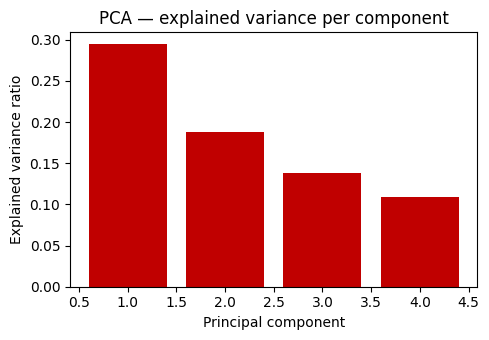

In [ ]:
# Quick look at the PCA explained variance (helps justify n_pca_components)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(range(1, fe.n_pca_components + 1), fe.pca.explained_variance_ratio_, color="#C00000")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("PCA — explained variance per component")
plt.tight_layout()
plt.show()


## 3. Model Training — CO2, CO3, CO5

- **Logistic Regression**: linear baseline trained with cross-entropy loss (scikit-learn's default
  objective); `C` (inverse L2 regularisation strength) is tuned to manage the bias-variance trade-off.
- **Random Forest**: ensemble of trees using bagging + random feature subsampling to reduce variance
  and capture non-linear feature interactions that Logistic Regression cannot.
- Both are tuned with **GridSearchCV** scored on ROC-AUC, using **stratified 5-fold cross-validation**
  so the class imbalance is respected in every fold and the held-out test set is never touched during
  tuning (avoiding data leakage).

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "logistic_regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"C": [0.01, 0.1, 1.0, 10.0], "class_weight": [None, "balanced"]},
    ),
    "random_forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {
            "n_estimators": [200, 400],
            "max_depth": [None, 6, 10],
            "max_features": ["sqrt", "log2"],
            "min_samples_leaf": [1, 2, 4],
            "class_weight": [None, "balanced"],
        },
    ),
}

fitted_models = {}
cv_results = {}

for name, (estimator, grid) in search_space.items():
    search = GridSearchCV(estimator, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_
    cv_results[name] = {"best_params": search.best_params_, "cv_best_roc_auc": round(search.best_score_, 4)}
    print(f"[{name}] best CV ROC-AUC = {search.best_score_:.4f} | params = {search.best_params_}")


[logistic_regression] best CV ROC-AUC = 0.8472 | params = {'C': 0.1, 'class_weight': None}
[random_forest] best CV ROC-AUC = 0.8415 | params = {'class_weight': 'balanced', 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 400}


## 4. Evaluation — CO3, CO5

Metrics, ROC / Precision-Recall curves, a calibration curve, confusion matrices, and Random
Forest feature importance — all computed on the **held-out test set** the tuning step never saw.

In [ ]:
def evaluate(name, model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return {
        "accuracy": round(accuracy_score(y, y_pred), 4),
        "precision": round(precision_score(y, y_pred), 4),
        "recall": round(recall_score(y, y_pred), 4),
        "f1": round(f1_score(y, y_pred), 4),
        "roc_auc": round(roc_auc_score(y, y_proba), 4),
        "pr_auc": round(average_precision_score(y, y_proba), 4),
    }

test_metrics = {name: evaluate(name, model, X_test, y_test) for name, model in fitted_models.items()}
pd.DataFrame(test_metrics).T


,accuracy,precision,recall,f1,roc_auc,pr_auc
logistic_regression,0.6948,0.5745,0.5000,0.5347,0.8050,0.6579
random_forest,0.7468,0.6154,0.7407,0.6723,0.8152,0.7079


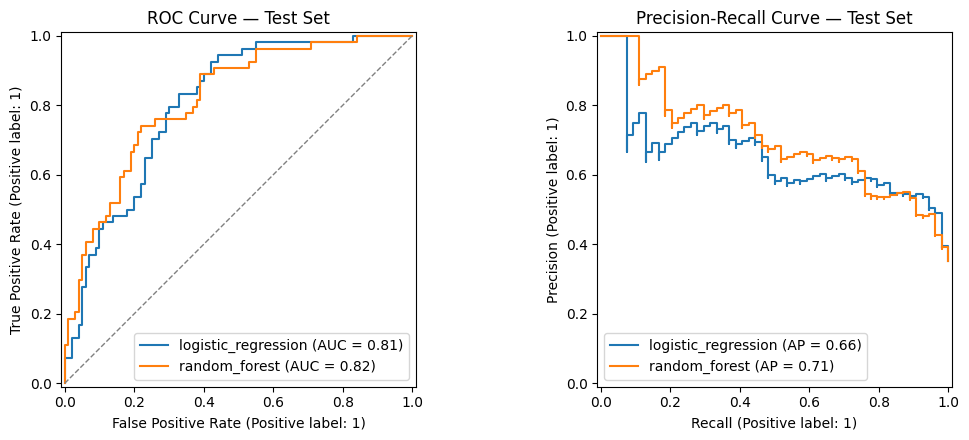

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[0].set_title("ROC Curve — Test Set")
axes[1].set_title("Precision-Recall Curve — Test Set")
plt.tight_layout()
plt.show()


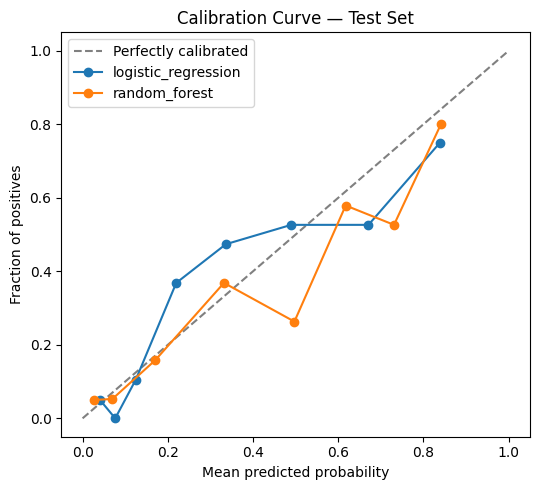

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfectly calibrated")
for name, model in fitted_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.set_title("Calibration Curve — Test Set")
ax.legend()
plt.tight_layout()
plt.show()


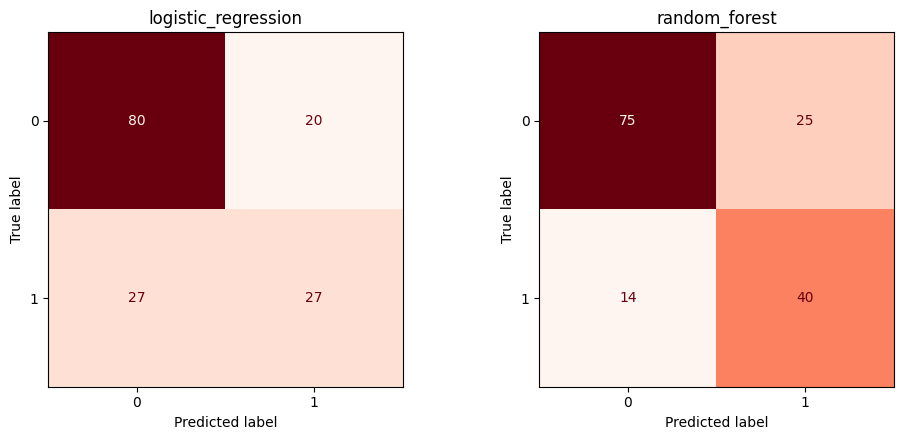

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, model) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Reds", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


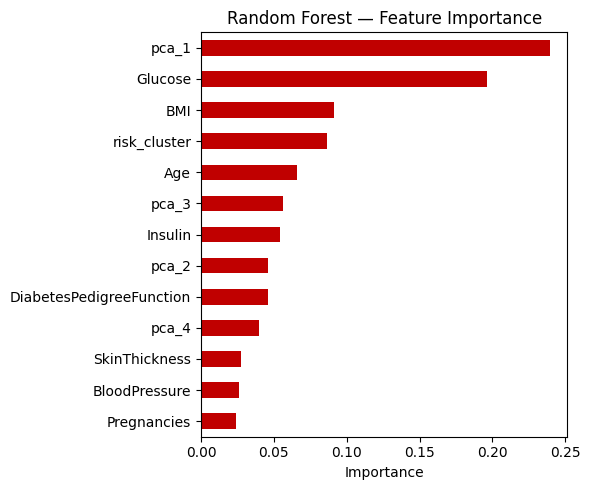

,0
pca_1,0.239521
Glucose,0.196439
BMI,0.091052
risk_cluster,0.086691
Age,0.066018
pca_3,0.056042
Insulin,0.054465
pca_2,0.045981
DiabetesPedigreeFunction,0.045825
pca_4,0.040083


In [ ]:
importances = pd.Series(
    fitted_models["random_forest"].feature_importances_, index=feature_cols
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(6, 5))
importances.plot(kind="barh", ax=ax, color="#C00000")
ax.set_title("Random Forest — Feature Importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False)


## 5. Model Packaging — CO6

Persist the fitted `FeatureEngineer` (imputer + scaler + PCA + K-means) alongside both trained
models with `joblib`. Packaging the preprocessing object together with the model is what lets the
serving code in Section 6 reuse the *exact* fitted transforms — no re-fitting, no drift between
training and inference.

In [ ]:
joblib.dump(fe, MODELS_DIR / "feature_engineer.joblib")
for name, model in fitted_models.items():
    joblib.dump(model, MODELS_DIR / f"{name}.joblib")

with open(REPORTS_DIR / "cv_search_results.json", "w") as f:
    json.dump(cv_results, f, indent=2)
with open(REPORTS_DIR / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

print("Saved artifacts to:", MODELS_DIR)
print(list(MODELS_DIR.glob("*.joblib")))

# Optional: pull the trained artifacts down to your own machine
# from google.colab import files
# files.download(str(MODELS_DIR / "random_forest.joblib"))


Saved artifacts to: /content/diabetes_project/models
[PosixPath('/content/diabetes_project/models/logistic_regression.joblib'), PosixPath('/content/diabetes_project/models/feature_engineer.joblib'), PosixPath('/content/diabetes_project/models/random_forest.joblib')]


## 6. Deployment — REST API with FastAPI — CO6

Wraps both models behind a `/predict` endpoint and adds a tiny `/monitoring/summary` endpoint that
compares the rolling mean predicted probability of recent requests against the training-time
baseline — a cheap first line of defence against input/concept drift in production.

**Tracing one request back through the lifecycle (CO1):** a call to `/predict` → runs the *same*
fitted `FeatureEngineer` from Section 2 (impute → scale → PCA → K-means cluster) → feeds the
resulting feature vector to the model chosen in Section 3 → returns a probability whose reliability
was already checked by the calibration curve in Section 4 → and every prediction it makes is logged
for the drift check in `/monitoring/summary`.

This cell uses FastAPI's `TestClient`, which calls the app in-process — perfect for demonstrating
the API inside a Colab cell without needing a public tunnel. To expose it publicly from Colab
instead, see the commented block at the end of the cell.

In [ ]:
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from typing import Literal

app = FastAPI(title="Diabetes Risk Prediction API")

_monitor_log = {name: deque(maxlen=200) for name in fitted_models}
_baseline_mean_proba = {
    name: float(np.mean(model.predict_proba(X_train)[:, 1]))
    for name, model in fitted_models.items()
}

class PatientRecord(BaseModel):
    Pregnancies: float = Field(..., ge=0)
    Glucose: float = Field(..., ge=0)
    BloodPressure: float = Field(..., ge=0)
    SkinThickness: float = Field(..., ge=0)
    Insulin: float = Field(..., ge=0)
    BMI: float = Field(..., ge=0)
    DiabetesPedigreeFunction: float = Field(..., ge=0)
    Age: float = Field(..., ge=0)

@app.get("/health")
def health():
    return {"status": "ok", "models_loaded": list(fitted_models.keys())}

@app.post("/predict")
def predict(record: PatientRecord, model_name: Literal["logistic_regression", "random_forest"] = "random_forest"):
    if model_name not in fitted_models:
        raise HTTPException(status_code=400, detail=f"Unknown model '{model_name}'")
    start = time.perf_counter()
    raw_df = pd.DataFrame([record.model_dump()])[FEATURE_COLUMNS]
    features = fe.transform(raw_df)
    proba = float(fitted_models[model_name].predict_proba(features[feature_cols])[0, 1])
    latency_ms = (time.perf_counter() - start) * 1000
    _monitor_log[model_name].append(proba)
    return {
        "model_used": model_name,
        "risk_probability": round(proba, 4),
        "risk_label": int(proba >= 0.5),
        "latency_ms": round(latency_ms, 3),
    }

@app.get("/monitoring/summary")
def monitoring_summary():
    summary = {}
    for name, log in _monitor_log.items():
        if not log:
            summary[name] = {"requests_logged": 0}
            continue
        recent_mean = float(np.mean(log))
        baseline = _baseline_mean_proba[name]
        drift = round(recent_mean - baseline, 4)
        summary[name] = {
            "requests_logged": len(log),
            "rolling_mean_probability": round(recent_mean, 4),
            "training_baseline_mean_probability": round(baseline, 4),
            "probability_drift": drift,
            "drift_flag": abs(drift) > 0.15,
        }
    return summary


# ---- Try it out in-process (no server needed) ----
from fastapi.testclient import TestClient
client = TestClient(app)

print(client.get("/health").json())

sample_patient = {
    "Pregnancies": 6, "Glucose": 148, "BloodPressure": 72, "SkinThickness": 35,
    "Insulin": 0, "BMI": 33.6, "DiabetesPedigreeFunction": 0.627, "Age": 50,
}
print(client.post("/predict?model_name=random_forest", json=sample_patient).json())
print(client.post("/predict?model_name=logistic_regression", json=sample_patient).json())
print(client.get("/monitoring/summary").json())

# ---- To actually serve this publicly from Colab, run in a NEW cell: ----
# import nest_asyncio, uvicorn
# nest_asyncio.apply()
# uvicorn.run(app, host="0.0.0.0", port=8000)
# # then, in another cell, expose it with a tunnel, e.g. pyngrok:
# # from pyngrok import ngrok
# # public_url = ngrok.connect(8000)
# # print(public_url)


{'status': 'ok', 'models_loaded': ['logistic_regression', 'random_forest']}
{'model_used': 'random_forest', 'risk_probability': 0.8039, 'risk_label': 1, 'latency_ms': 278.994}
{'model_used': 'logistic_regression', 'risk_probability': 0.6924, 'risk_label': 1, 'latency_ms': 41.644}
{'logistic_regression': {'requests_logged': 1, 'rolling_mean_probability': 0.6924, 'training_baseline_mean_probability': 0.3486, 'probability_drift': 0.3439, 'drift_flag': True}, 'random_forest': {'requests_logged': 1, 'rolling_mean_probability': 0.8039, 'training_baseline_mean_probability': 0.412, 'probability_drift': 0.3918, 'drift_flag': True}}


In [ ]:
h

## Summary

- **CO1**: data → `FeatureEngineer` → `GridSearchCV`-tuned Logistic Regression / Random Forest → held-out evaluation → `joblib` packaging → FastAPI serving → rolling drift monitor.
- **CO2**: Logistic Regression with L2 regularisation, `C` tuned by cross-validation, all features standardised beforehand.
- **CO3**: Random Forest with bagging + feature subsampling; feature importances highlight `pca_1`, `Glucose`, and `risk_cluster` as the strongest predictors.
- **CO4**: PCA condenses correlated clinical measurements; K-means contributes a `risk_cluster` feature that shows up as one of the more important Random Forest features.
- **CO5**: Stratified 5-fold CV drives model selection; test-set accuracy, precision, recall, F1, ROC-AUC, PR-AUC, and a calibration curve are all reported.
- **CO6**: Model + preprocessing packaged with `joblib`; served via a FastAPI `/predict` endpoint; a `/monitoring/summary` endpoint flags probability drift against the training baseline.
